In [12]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import os
import time
import copy
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
BATCH_SIZE = 32
EPOCHS = 15
PATIENCE = 3
NUM_WORKERS = 2

ROOT = "/content/data"
OUT = "/content/drive/MyDrive/Tugas05/hasil"

os.makedirs(ROOT, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [14]:
trainval_data = datasets.OxfordIIITPet(
    root=ROOT,
    split="trainval",
    target_types="category",
    download=True
)

test_data = datasets.OxfordIIITPet(
    root=ROOT,
    split="test",
    target_types="category",
    download=True
)

print("Trainval:", len(trainval_data))
print("Test:", len(test_data))
print("Kelas:", trainval_data.classes)


Trainval: 3680
Test: 3669
Kelas: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


In [15]:

classes = [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Bombay",
    "Persian",
    "American Bulldog",
    "American Pit Bull Terrier",
    "Basset Hound",
    "Beagle",
    "Boxer"
]

class_to_idx = {name: i for i, name in enumerate(classes)}

original_classes = trainval_data.classes

assert all(c in original_classes for c in classes), ("Ada nama kelas yang tidak ditemukan.")

print("Jumlah kelas:", len(classes))
print(class_to_idx)


Jumlah kelas: 10
{'Abyssinian': 0, 'Bengal': 1, 'Birman': 2, 'Bombay': 3, 'Persian': 4, 'American Bulldog': 5, 'American Pit Bull Terrier': 6, 'Basset Hound': 7, 'Beagle': 8, 'Boxer': 9}


In [16]:
all_paths = trainval_data._images + test_data._images
all_labels = trainval_data._labels + test_data._labels

indices = [i for i, label in enumerate(all_labels) if original_classes[label] in classes]

y = [class_to_idx[original_classes[all_labels[i]]] for i in indices]

train_idx, temp_idx = train_test_split(
    indices, test_size=0.30,
    random_state=SEED, stratify=y
)

temp_y = [
    class_to_idx[original_classes[all_labels[i]]]
    for i in temp_idx
]

val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50,
    random_state=SEED, stratify=temp_y
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))


Train: 1386
Validation: 297
Test: 298


In [17]:

weights = models.ResNet18_Weights.IMAGENET1K_V1

train_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        weights.transforms().mean,
        weights.transforms().std
    )
])

no_aug_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        weights.transforms().mean,
        weights.transforms().std
    )
])

eval_tf = weights.transforms()

class PetDataset(Dataset):
    def __init__(self, indices, transform):
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        i = self.indices[idx]
        image = Image.open(all_paths[i]).convert("RGB")
        label = class_to_idx[original_classes[all_labels[i]]]
        return self.transform(image), label

def loaders(augment=True):
    train_ds = PetDataset(
        train_idx, train_tf if augment else no_aug_tf
    )
    val_ds = PetDataset(val_idx, eval_tf)
    test_ds = PetDataset(test_idx, eval_tf)

    return (
        DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True),
        DataLoader(val_ds, batch_size=BATCH_SIZE),
        DataLoader(test_ds, batch_size=BATCH_SIZE)
    )

train_loader, val_loader, test_loader = loaders()
print("DataLoader siap.")


DataLoader siap.


In [18]:
def build_model(strategy):
    if strategy == "B1":
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, 10)
        params = [{"params": model.parameters(), "lr": 1e-3}]

    else:
        model = models.resnet18(weights=weights)

        for p in model.parameters():
            p.requires_grad = False

        model.fc = nn.Linear(model.fc.in_features, 10)

        if strategy == "B2":
            params = [{"params": model.fc.parameters(), "lr": 1e-3}]

        else:
            for p in model.layer4.parameters():
                p.requires_grad = True

            params = [
                {"params": model.layer4.parameters(), "lr": 1e-4},
                {"params": model.fc.parameters(), "lr": 1e-3}
            ]

    return model.to(device), params


In [20]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    loss_fn = nn.CrossEntropyLoss()
    loss_sum, correct, total = 0, 0, 0

    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            if training:
                optimizer.zero_grad()

            output = model(x)
            loss = loss_fn(output, y)

            if training:
                loss.backward()
                optimizer.step()

            loss_sum += loss.item() * len(y)
            correct += (output.argmax(1) == y).sum().item()
            total += len(y)

    return loss_sum / total, correct / total


In [22]:
def experiment(name, strategy, augment=True):
    tr, va, te = loaders(augment)
    model, params = build_model(strategy)
    optimizer = torch.optim.AdamW(params, weight_decay=1e-2)

    best_loss, best_state, patience = float("inf"), None, 0
    history = {"train_loss": [], "val_loss": []}
    start = time.time()

    for epoch in range(EPOCHS):
        tl, _ = run_epoch(model, tr, optimizer)
        vl, _ = run_epoch(model, va)

        history["train_loss"].append(tl)
        history["val_loss"].append(vl)
        print(f"{name} | Epoch {epoch+1}: train={tl:.4f}, val={vl:.4f}")

        if vl < best_loss:
            best_loss = vl
            best_state = copy.deepcopy(model.state_dict())
            patience = 0
        else:
            patience += 1
            if patience >= PATIENCE:
                break

    model.load_state_dict(best_state)

    y_true, y_pred = [], []
    with torch.no_grad():
        model.eval()
        for x, y in te:
            pred = model(x.to(device)).argmax(1).cpu()
            y_true.extend(y.numpy())
            y_pred.extend(pred.numpy())

    result = {
        "experiment": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "duration": round(time.time() - start, 2),
        "best_val_loss": best_loss
    }

    return model, history, result, (y_true, y_pred)


In [23]:
b1 = experiment("B1 Scratch", "B1", True)
b2 = experiment("B2 Feature Extraction", "B2", True)
b3 = experiment("B3 Fine-Tuning", "B3", True)

b4_no = experiment("B4 Without Augmentation", "B2", False)
b4_aug = experiment("B4 With Augmentation", "B2", True)

results = [b1[2], b2[2], b3[2], b4_no[2], b4_aug[2]]
df = pd.DataFrame(results)
display(df)

df.to_csv(f"{OUT}/metrics_summary.csv", index=False)


B1 Scratch | Epoch 1: train=2.2618, val=2.1834
B1 Scratch | Epoch 2: train=2.0016, val=2.9144
B1 Scratch | Epoch 3: train=1.8638, val=2.3853
B1 Scratch | Epoch 4: train=1.7895, val=2.0856
B1 Scratch | Epoch 5: train=1.6926, val=1.8250
B1 Scratch | Epoch 6: train=1.6856, val=1.9071
B1 Scratch | Epoch 7: train=1.6013, val=1.5578
B1 Scratch | Epoch 8: train=1.5905, val=1.7646
B1 Scratch | Epoch 9: train=1.5261, val=1.8586
B1 Scratch | Epoch 10: train=1.4498, val=1.7272
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 231MB/s]


B2 Feature Extraction | Epoch 1: train=1.5725, val=0.8057
B2 Feature Extraction | Epoch 2: train=0.7286, val=0.4613
B2 Feature Extraction | Epoch 3: train=0.5104, val=0.3540
B2 Feature Extraction | Epoch 4: train=0.4415, val=0.3040
B2 Feature Extraction | Epoch 5: train=0.3819, val=0.2649
B2 Feature Extraction | Epoch 6: train=0.3495, val=0.2804
B2 Feature Extraction | Epoch 7: train=0.3303, val=0.2483
B2 Feature Extraction | Epoch 8: train=0.2880, val=0.2424
B2 Feature Extraction | Epoch 9: train=0.2743, val=0.2254
B2 Feature Extraction | Epoch 10: train=0.2687, val=0.2156
B2 Feature Extraction | Epoch 11: train=0.2502, val=0.2337
B2 Feature Extraction | Epoch 12: train=0.2437, val=0.2241
B2 Feature Extraction | Epoch 13: train=0.2408, val=0.2253
B3 Fine-Tuning | Epoch 1: train=0.8431, val=0.2285
B3 Fine-Tuning | Epoch 2: train=0.2636, val=0.2022
B3 Fine-Tuning | Epoch 3: train=0.1327, val=0.2072
B3 Fine-Tuning | Epoch 4: train=0.0889, val=0.2131
B3 Fine-Tuning | Epoch 5: train=0.0728

,experiment,accuracy,macro_f1,duration,best_val_loss
0,B1 Scratch,0.429530,0.396788,208.61,1.557824
1,B2 Feature Extraction,0.926174,0.926712,219.42,0.215642
2,B3 Fine-Tuning,0.932886,0.933001,87.20,0.202189
3,B4 Without Augmentation,0.932886,0.933787,182.74,0.207453
4,B4 With Augmentation,0.922819,0.923582,227.16,0.232531


In [28]:
res_b5 = experiment(
    "B5 EfficientNet-B0",
    "B5",
    augment=True
)

print(res_b5[2])


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 97.5MB/s]


B5 EfficientNet-B0 | Epoch 1: train=1.5451, val=0.8935
B5 EfficientNet-B0 | Epoch 2: train=0.7835, val=0.5562
B5 EfficientNet-B0 | Epoch 3: train=0.5920, val=0.4466
B5 EfficientNet-B0 | Epoch 4: train=0.4746, val=0.4041
B5 EfficientNet-B0 | Epoch 5: train=0.4431, val=0.3582
B5 EfficientNet-B0 | Epoch 6: train=0.3767, val=0.3409
B5 EfficientNet-B0 | Epoch 7: train=0.3678, val=0.3160
B5 EfficientNet-B0 | Epoch 8: train=0.3546, val=0.2953
B5 EfficientNet-B0 | Epoch 9: train=0.3031, val=0.2813
B5 EfficientNet-B0 | Epoch 10: train=0.2994, val=0.2672
B5 EfficientNet-B0 | Epoch 11: train=0.2859, val=0.2652
B5 EfficientNet-B0 | Epoch 12: train=0.2890, val=0.2674
B5 EfficientNet-B0 | Epoch 13: train=0.2649, val=0.2659
B5 EfficientNet-B0 | Epoch 14: train=0.2476, val=0.2386
B5 EfficientNet-B0 | Epoch 15: train=0.2355, val=0.2301
{'experiment': 'B5 EfficientNet-B0', 'accuracy': 0.9161073825503355, 'macro_f1': 0.9162951724835645, 'duration': 273.42, 'best_val_loss': 0.23011696052671682}


In [41]:
def validation_accuracy(model):
    _, val_loader, _ = loaders(augment=True)
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            pred = model(x).argmax(1)
            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total


runs = [
    ("B1", b1),
    ("B2", b2),
    ("B3", b3),
    ("B4 No Aug", b4_no),
    ("B4 With Aug", b4_aug),
    ("B5", res_b5)
]

for name, run in runs:
    print(f"{name}: {validation_accuracy(run[0]):.4%}")


B1: 45.1178%
B2: 94.6128%
B3: 94.6128%
B4 No Aug: 93.2660%
B4 With Aug: 92.5926%
B5: 94.2761%


In [42]:
results = [
    b1[2],
    b2[2],
    b3[2],
    b4_no[2],
    b4_aug[2],
    res_b5[2]
]

df = pd.DataFrame(results)
display(df)


,experiment,accuracy,macro_f1,duration,best_val_loss
0,B1 Scratch,0.429530,0.396788,208.61,1.557824
1,B2 Feature Extraction,0.926174,0.926712,219.42,0.215642
2,B3 Fine-Tuning,0.932886,0.933001,87.20,0.202189
3,B4 Without Augmentation,0.932886,0.933787,182.74,0.207453
4,B4 With Augmentation,0.922819,0.923582,227.16,0.232531
5,B5 EfficientNet-B0,0.916107,0.916295,273.42,0.230117


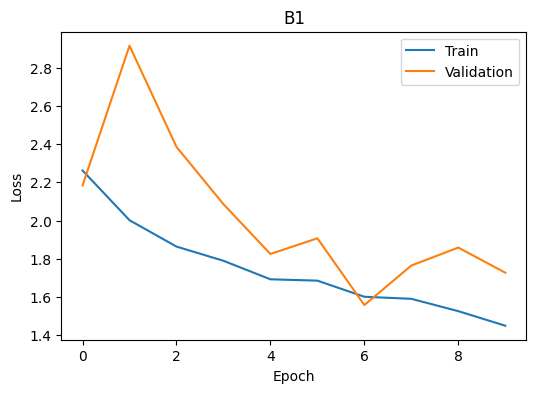

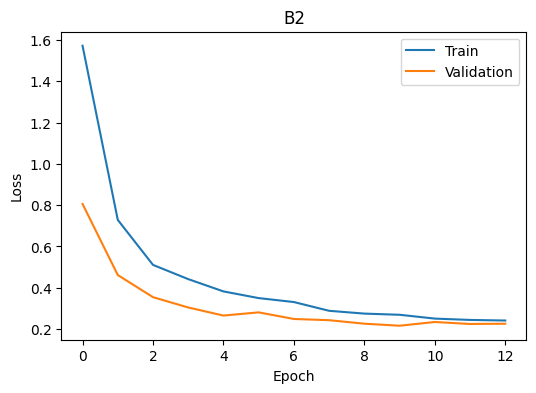

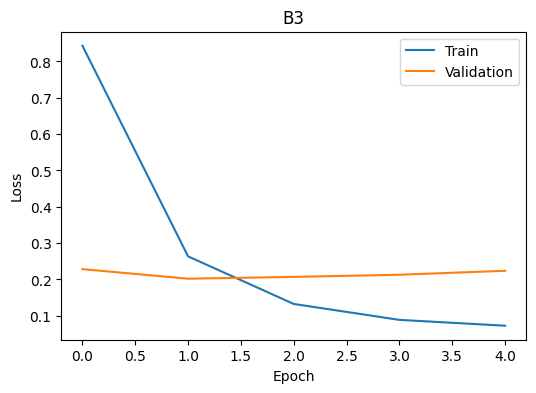

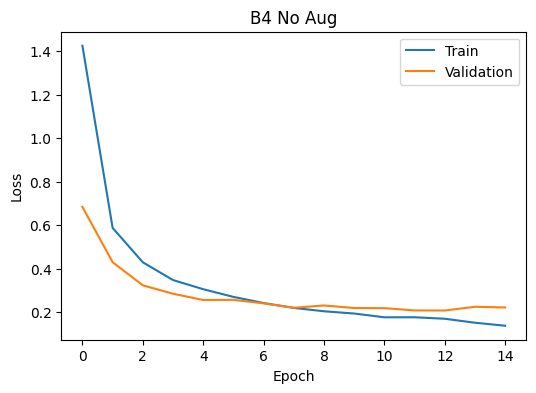

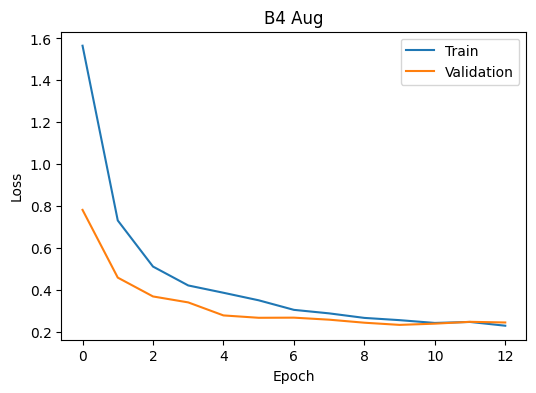

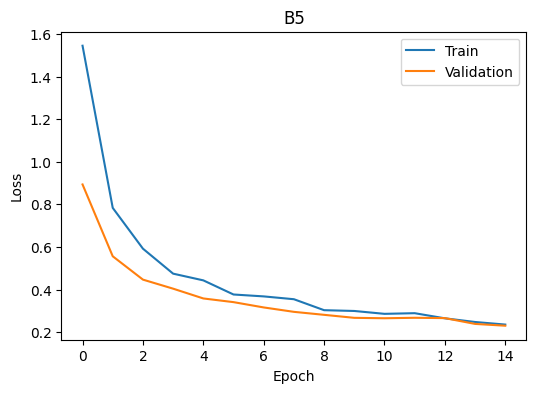

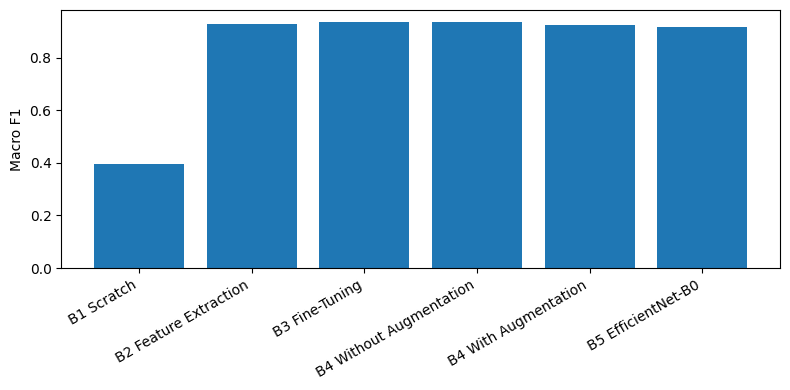

In [43]:
for name, run in [
    ("B1", b1), ("B2", b2), ("B3", b3),
    ("B4 No Aug", b4_no), ("B4 Aug", b4_aug), ("B5", res_b5)
]:
    plt.figure(figsize=(6, 4))
    plt.plot(run[1]["train_loss"], label="Train")
    plt.plot(run[1]["val_loss"], label="Validation")
    plt.title(name)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

plt.figure(figsize=(8, 4))
plt.bar(df["experiment"], df["macro_f1"])
plt.xticks(rotation=30, ha="right")
plt.ylabel("Macro F1")
plt.tight_layout()
plt.show()


                           precision    recall  f1-score   support

               Abyssinian       0.96      0.90      0.93        30
                   Bengal       0.91      0.97      0.94        30
                   Birman       1.00      0.97      0.98        30
                   Bombay       1.00      1.00      1.00        28
                  Persian       0.97      1.00      0.98        30
         American Bulldog       0.93      0.83      0.88        30
American Pit Bull Terrier       0.87      0.87      0.87        30
             Basset Hound       0.94      0.97      0.95        30
                   Beagle       0.87      0.87      0.87        30
                    Boxer       0.91      0.97      0.94        30

                 accuracy                           0.93       298
                macro avg       0.93      0.93      0.93       298
             weighted avg       0.93      0.93      0.93       298



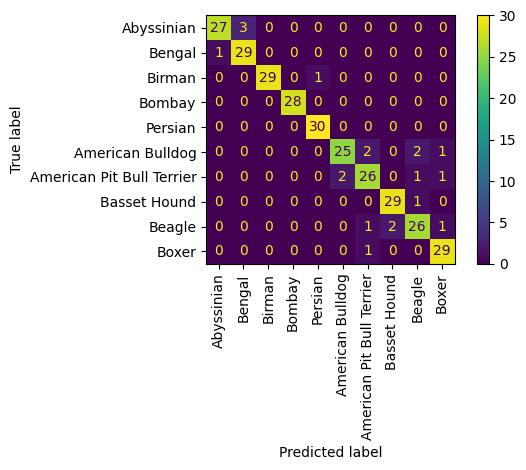

Hasil tersimpan di: /content/drive/MyDrive/Tugas05/hasil


In [44]:
runs = [b1, b2, b3, b4_no, b4_aug, res_b5]
best = min(runs, key=lambda r: r[2]["best_val_loss"])

y_true, y_pred = best[3]

print(classification_report(
    y_true, y_pred, target_names=classes, zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix(y_true, y_pred),
    display_labels=classes
).plot(xticks_rotation=90)

plt.tight_layout()
plt.show()

with open(f"{OUT}/results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Hasil tersimpan di:", OUT)


In [47]:
runs = [
    ("B1", "From Scratch", b1, "1e-3"),
    ("B2", "Feature Extraction", b2, "1e-3"),
    ("B3", "Fine-Tuning", b3, "layer4: 1e-4; fc: 1e-3"),
    ("B4 No Aug", "Feature Extraction tanpa Augmentation",
     b4_no, "1e-3"),
    ("B4 With Aug", "Feature Extraction dengan Augmentation",
     b4_aug, "1e-3"),
    ("B5", "EfficientNet-B0", res_b5, "1e-3")
]

rows = []

for name, strategy, run, lr in runs:
    model, history, result = run[:3]

    val_acc = validation_accuracy(model)

    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    rows.append({
        "Eksperimen": name,
        "Strategi": strategy,
        "Trainable Parameters": trainable,
        "Learning Rate": lr,
        "Epoch Konvergen": (
            result.get("best_epoch")
            or int(np.argmin(history["val_loss"])) + 1
        ),
        "Waktu Training (s)": result["duration"],
        "Akurasi Validasi (%)": round(val_acc * 100, 2),
        "Macro F1 Test (%)": round(result["macro_f1"] * 100, 2)
    })

table_c1 = pd.DataFrame(rows)
display(table_c1)

table_c1.to_csv(
    f"{OUT}/C1_tabel_konsolidasi.csv", index=False
)

table_c1.to_excel(
    f"{OUT}/C1_tabel_konsolidasi.xlsx", index=False
)


,Eksperimen,Strategi,Trainable Parameters,Learning Rate,Epoch Konvergen,Waktu Training (s),Akurasi Validasi (%),Macro F1 Test (%)
0,B1,From Scratch,11181642,1e-3,7,208.61,45.12,39.68
1,B2,Feature Extraction,5130,1e-3,10,219.42,94.61,92.67
2,B3,Fine-Tuning,8398858,layer4: 1e-4; fc: 1e-3,2,87.20,94.61,93.30
3,B4 No Aug,Feature Extraction tanpa Augmentation,5130,1e-3,13,182.74,93.27,93.38
4,B4 With Aug,Feature Extraction dengan Augmentation,5130,1e-3,10,227.16,92.59,92.36
5,B5,EfficientNet-B0,12810,1e-3,15,273.42,94.28,91.63


Jumlah sampel salah ditemukan: 8


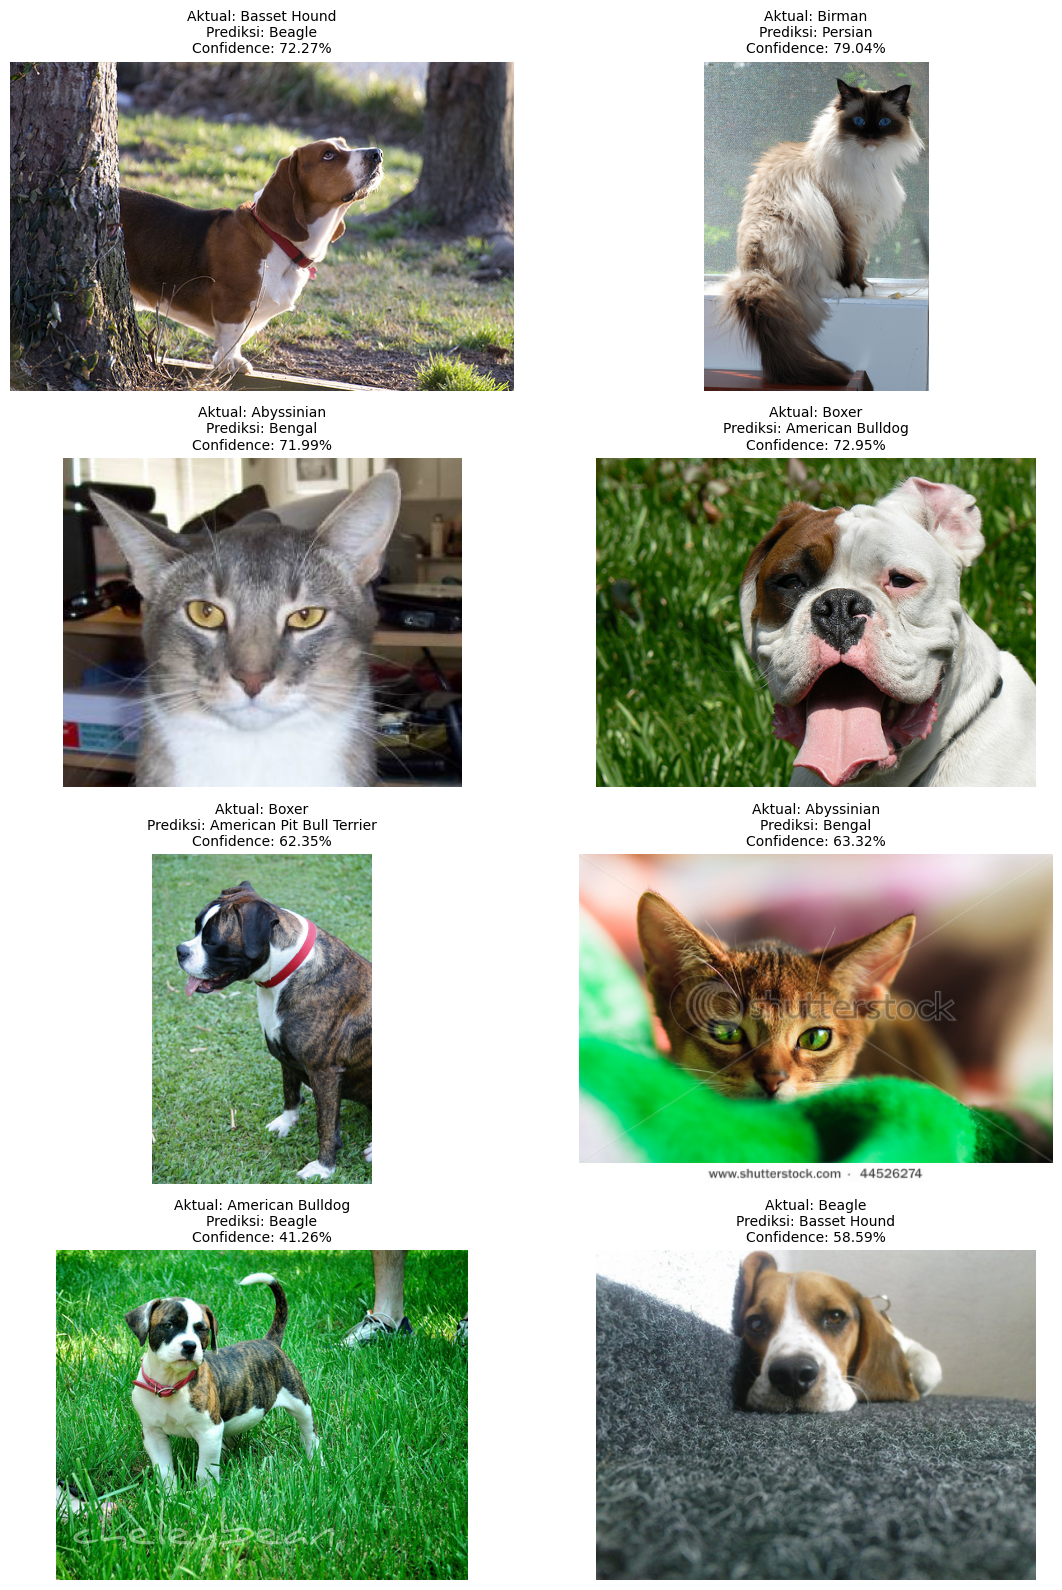

In [48]:
from PIL import Image
from torch.utils.data import DataLoader

model = b4_no[0]
model.eval()

test_ds = PetDataset(test_idx, eval_tf)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False
)

errors = []
position = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        probs = torch.softmax(outputs, dim=1)
        confidence, predictions = probs.max(dim=1)

        for j in range(len(labels)):
            actual = labels[j].item()
            pred = predictions[j].item()

            if actual != pred:
                errors.append({
                    "index": test_idx[position],
                    "actual": actual,
                    "pred": pred,
                    "confidence": confidence[j].item()
                })

            position += 1

        if len(errors) >= 8:
            break

print("Jumlah sampel salah ditemukan:", len(errors))

n = min(8, len(errors))
fig, axes = plt.subplots(
    (n + 1) // 2, 2, figsize=(12, 4 * ((n + 1) // 2))
)
axes = np.array(axes).reshape(-1)

for ax, item in zip(axes, errors[:8]):
    image = Image.open(all_paths[item["index"]]).convert("RGB")
    ax.imshow(image)
    ax.set_title(
        f"Aktual: {classes[item['actual']]}\n"
        f"Prediksi: {classes[item['pred']]}\n"
        f"Confidence: {item['confidence']:.2%}",
        fontsize=10
    )
    ax.axis("off")

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(f"{OUT}/C3_misclassification.png", dpi=300)
plt.show()


In [53]:
import torch.nn.functional as F

def gradcam(model, image, class_idx=None):
    model.eval()
    activations = []
    x = image.unsqueeze(0).to(device)

    def forward_hook(module, inputs, output):
        activations.append(output)
        output.register_hook(
            lambda grad: gradients.append(grad)
        )

    gradients = []
    handle = model.layer4.register_forward_hook(forward_hook)

    output = model(x)
    idx = output.argmax(1).item() if class_idx is None else class_idx

    model.zero_grad()
    output[0, idx].backward()
    handle.remove()

    weights = gradients[0].mean(dim=(2, 3), keepdim=True)
    cam = (weights * activations[0]).sum(dim=1, keepdim=True)
    cam = F.relu(cam)
    cam = F.interpolate(
        cam, size=(224, 224),
        mode="bilinear", align_corners=False
    )[0, 0]

    cam = cam.detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam


In [62]:
import torch.nn.functional as F


def gradcam(model, image):
    model.eval()
    activations = []

    def forward_hook(module, inputs, output):
        activations.append(output)

    handle = model.layer4.register_forward_hook(forward_hook)

    try:
        with torch.enable_grad():
            x = image.unsqueeze(0).to(device).requires_grad_(True)
            output = model(x)
            pred = output.argmax(dim=1).item()

            act = activations[0]
            grad = torch.autograd.grad(
                outputs=output[0, pred],
                inputs=act
            )[0]

            weights = grad.mean(dim=(2, 3), keepdim=True)
            cam = F.relu((weights * act).sum(dim=1, keepdim=True))

            cam = F.interpolate(
                cam,
                size=image.shape[1:],
                mode="bilinear",
                align_corners=False
            )[0, 0]

            cam = cam.detach().cpu().numpy()
            cam = cam / (cam.max() + 1e-8)

        return cam, pred

    finally:
        handle.remove()


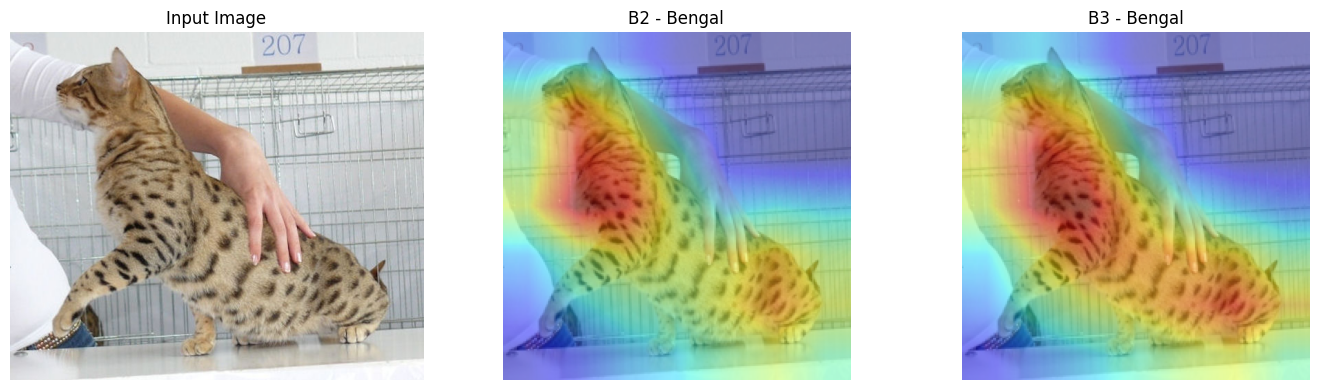

In [63]:
cam_b2, pred_b2 = gradcam(b2[0], x)
cam_b3, pred_b3 = gradcam(b3[0], x)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(img)
axes[0].set_title("Input Image")

axes[1].imshow(img.resize((224, 224)))
axes[1].imshow(cam_b2, cmap="jet", alpha=0.45)
axes[1].set_title(f"B2 - {classes[pred_b2]}")

axes[2].imshow(img.resize((224, 224)))
axes[2].imshow(cam_b3, cmap="jet", alpha=0.45)
axes[2].set_title(f"B3 - {classes[pred_b3]}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(f"{OUT}/C5_gradcam.png", dpi=300)
plt.show()
